#  Hotel Booking Demand – Data Cleaning & Analysis

**Project:** Hotel Booking Demand (Kaggle) | **Tools:** Python, Pandas, NumPy, Matplotlib
**Submitted by:** Ayush Sheldia (IU2441230475) and Mahit Khant (IU2441230539)
**Course/Program:** B.Tech – CSE-F | **Date:** 09 October 2026

---
### Project definition
This notebook cleans and analyses hotel booking data to find out **who books, when they book, and why bookings get cancelled**.
It delivers a cleaned dataset, seven charts (line + bar only), and a short insights report.

### Dataset
[Hotel Booking Demand on Kaggle](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand): about 119,390 bookings and 32 columns from a City Hotel and a Resort Hotel in Portugal (2015–2017). Key column: `is_canceled`.

### Use case
Hotel managers can use the results to reduce cancellations, set seasonal prices, and target the best customer segments.

### Notebook outline
1. Setup & load data
2. Data cleaning (missing values, duplicates, data types, outliers)
3. Seven visualizations
4. Short insights report
5. Export cleaned data and charts

## 1. Setup & Load Data

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.figsize": (9, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

os.makedirs("charts", exist_ok=True)
os.makedirs("data", exist_ok=True)

def save_chart(name):
    plt.tight_layout()
    plt.savefig(f"charts/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

**Loading the data.** The cell below downloads the same Hotel Booking Demand dataset from a public mirror (no Kaggle login needed).
If the download fails, it asks you to upload `hotel_bookings.csv` manually (download it from Kaggle first).

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"

try:
    df_raw = pd.read_csv(DATA_URL)
    print("Loaded from public URL.")
except Exception as e:
    print("Download failed:", e)
    print("Please upload hotel_bookings.csv from Kaggle.")
    from google.colab import files
    uploaded = files.upload()
    df_raw = pd.read_csv(list(uploaded.keys())[0])

df_raw.to_csv("data/hotel_bookings_raw.csv", index=False)
print("Raw shape:", df_raw.shape)
df_raw.head()

Loaded from public URL.


Raw shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### Quick look at the raw data

In [ ]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [ ]:
missing = df_raw.replace({"NULL": np.nan, "NA": np.nan}).isna().sum()
print("Missing values per column (treating 'NULL'/'NA' text as missing):")
print(missing[missing > 0])
print("\nExact duplicate rows:", df_raw.duplicated().sum())

Missing values per column (treating 'NULL'/'NA' text as missing):
children         4
country        488
agent        16340
company     112593
dtype: int64

Exact duplicate rows: 31994


## 2. Data Cleaning

Steps from the proposal:
- **Missing values:** fill `agent` and `children` with 0, fill `country` with "Unknown", drop `company`
- **Duplicates:** find and remove repeated rows
- **Data types:** convert dates to datetime and ID columns to categories
- **Outliers:** remove negative or extreme `adr` values and bookings with zero guests (IQR rule)

In [ ]:
df = df_raw.copy()
rows_before = len(df)
cols_before = df.shape[1]

# Some copies of the dataset store missing values as the text 'NULL' / 'NA'
df = df.replace({"NULL": np.nan, "NA": np.nan})

### 2.1 Missing values

In [ ]:
df["children"] = pd.to_numeric(df["children"], errors="coerce").fillna(0).astype(int)
df["agent"] = pd.to_numeric(df["agent"], errors="coerce").fillna(0).astype(int)
df["country"] = df["country"].fillna("Unknown")
df = df.drop(columns=["company"])

print("Remaining missing values:", int(df.isna().sum().sum()))

Remaining missing values: 0


### 2.2 Duplicates

In [ ]:
dups = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {dups:,}")
print(f"Rows now: {len(df):,}")

Duplicate rows removed: 32,001
Rows now: 87,389


### 2.3 Data types

In [ ]:
# Build a real arrival date from year / month name / day
df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-" +
    df["arrival_date_month"] + "-" +
    df["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d")
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"])

# ID-like columns -> category
for col in ["agent", "country"]:
    df[col] = df[col].astype("category")

# Year-month column used for the monthly line charts
df["arrival_month"] = df["arrival_date"].dt.to_period("M").dt.to_timestamp()

df[["arrival_date", "reservation_status_date", "agent", "country"]].dtypes

arrival_date               datetime64[us]
reservation_status_date    datetime64[us]
agent                            category
country                          category
dtype: object

### 2.4 Outliers
Remove: bookings with **zero guests**, **negative** `adr`, and **extreme** `adr` using the IQR rule
(values above Q3 + 1.5 × IQR).

In [ ]:
# Zero-guest bookings
guests = df["adults"] + df["children"] + df["babies"]
zero_guest = (guests == 0).sum()
df = df[guests > 0]

# ADR: negative values + IQR rule
q1, q3 = df["adr"].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
adr_bad = ((df["adr"] < 0) | (df["adr"] < lower) | (df["adr"] > upper)).sum()
df = df[(df["adr"] >= 0) & (df["adr"] >= lower) & (df["adr"] <= upper)].reset_index(drop=True)

print(f"ADR IQR bounds: {lower:.2f} to {upper:.2f}")
print(f"Zero-guest rows removed: {zero_guest:,}")
print(f"Negative/extreme ADR rows removed: {adr_bad:,}")

ADR IQR bounds: -20.52 to 226.88
Zero-guest rows removed: 166
Negative/extreme ADR rows removed: 2,509


### Cleaning summary (before vs after)

In [ ]:
rows_after = len(df)
summary = pd.DataFrame({
    "Metric": ["Rows", "Columns", "Missing values", "Duplicate rows"],
    "Before cleaning": [rows_before, cols_before, int(df_raw.replace({"NULL": np.nan, "NA": np.nan}).isna().sum().sum()), int(df_raw.duplicated().sum())],
    "After cleaning": [rows_after, df.shape[1], int(df.isna().sum().sum()), int(df.duplicated().sum())],
})
print(f"Rows removed in total: {rows_before - rows_after:,} ({(rows_before - rows_after) / rows_before:.1%})")
summary

Rows removed in total: 34,676 (29.0%)


,Metric,Before cleaning,After cleaning
0,Rows,119390,84714
1,Columns,32,33
2,Missing values,129425,0
3,Duplicate rows,31994,0


## 3. Visualizations
Only **line charts** and **bar charts** are used. Each chart has a title, labelled axes and a one-line takeaway (printed below the chart).

### Chart 1 – Bookings by hotel (cancelled vs not cancelled)

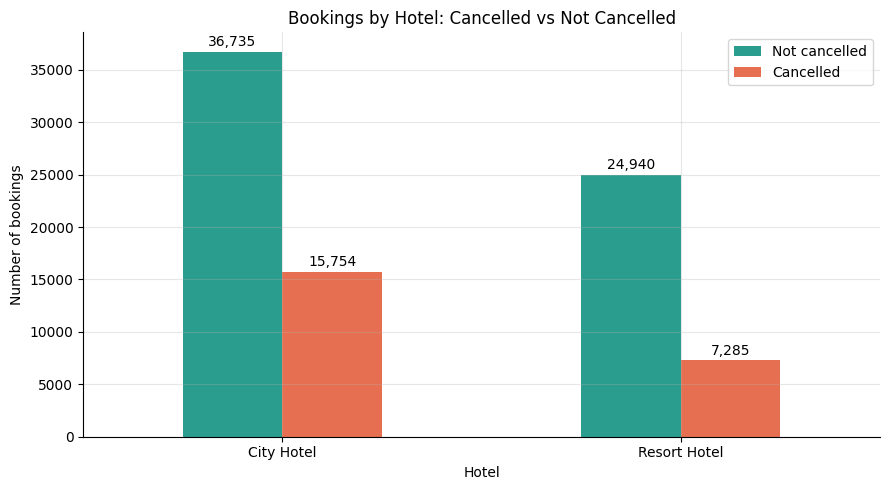

Takeaway: City Hotel has more bookings and a higher cancellation rate (30.0%) than Resort Hotel (22.6%).


In [ ]:
c1 = df.groupby(["hotel", "is_canceled"]).size().unstack(fill_value=0)
c1.columns = ["Not cancelled", "Cancelled"]

ax = c1.plot(kind="bar", color=["#2a9d8f", "#e76f51"], rot=0)
ax.set_title("Bookings by Hotel: Cancelled vs Not Cancelled")
ax.set_xlabel("Hotel")
ax.set_ylabel("Number of bookings")
for cont in ax.containers:
    ax.bar_label(cont, fmt="{:,.0f}", padding=2)
save_chart("01_bookings_by_hotel_cancellation")

rate = (c1["Cancelled"] / c1.sum(axis=1)).round(3) * 100
print(f"Takeaway: City Hotel has more bookings and a higher cancellation rate "
      f"({rate['City Hotel']:.1f}%) than Resort Hotel ({rate['Resort Hotel']:.1f}%).")

### Chart 2 – Number of bookings per month for each hotel

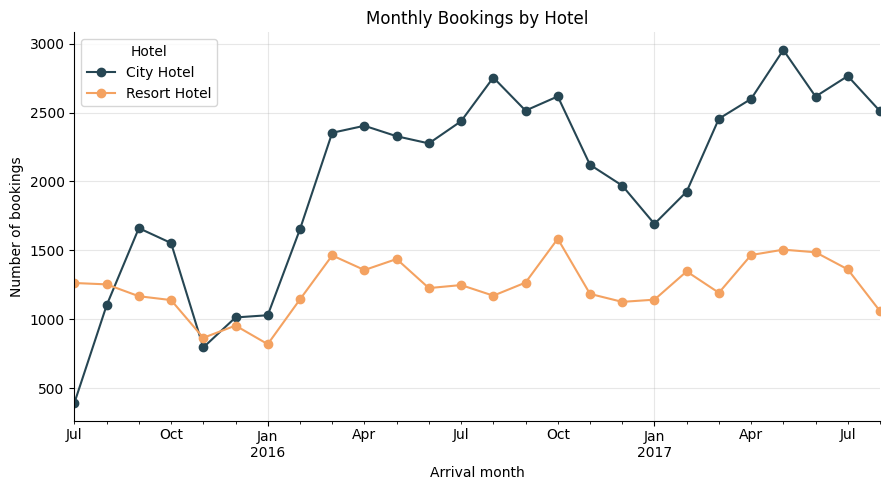

Takeaway: Averaged over all years, bookings are highest in August and lowest in January.


In [ ]:
c2 = df.groupby(["arrival_month", "hotel"]).size().unstack()

ax = c2.plot(kind="line", marker="o", color=["#264653", "#f4a261"])
ax.set_title("Monthly Bookings by Hotel")
ax.set_xlabel("Arrival month")
ax.set_ylabel("Number of bookings")
ax.legend(title="Hotel")
save_chart("02_monthly_bookings_by_hotel")

by_month = df.groupby(df["arrival_date"].dt.month_name()).size()
print(f"Takeaway: Averaged over all years, bookings are highest in {by_month.idxmax()} and lowest in {by_month.idxmin()}.")

### Chart 3 – Average daily rate (ADR) per month

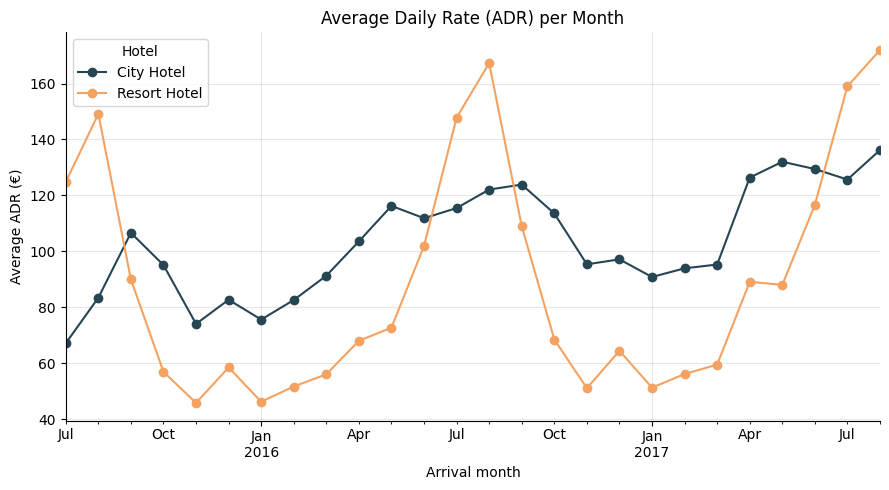

Takeaway: ADR is highest in August at the Resort Hotel (EUR 162) and in May at the City Hotel (EUR 125).


In [ ]:
c3 = df.groupby(["arrival_month", "hotel"])["adr"].mean().unstack()

ax = c3.plot(kind="line", marker="o", color=["#264653", "#f4a261"])
ax.set_title("Average Daily Rate (ADR) per Month")
ax.set_xlabel("Arrival month")
ax.set_ylabel("Average ADR (€)")
ax.legend(title="Hotel")
save_chart("03_monthly_adr")

adr_m = df.groupby([df["arrival_date"].dt.month_name(), "hotel"])["adr"].mean().unstack()
print(f"Takeaway: ADR is highest in {adr_m['Resort Hotel'].idxmax()} at the Resort Hotel (EUR {adr_m['Resort Hotel'].max():.0f}) "
      f"and in {adr_m['City Hotel'].idxmax()} at the City Hotel (EUR {adr_m['City Hotel'].max():.0f}).")

### Chart 4 – Cancellation rate by lead time group

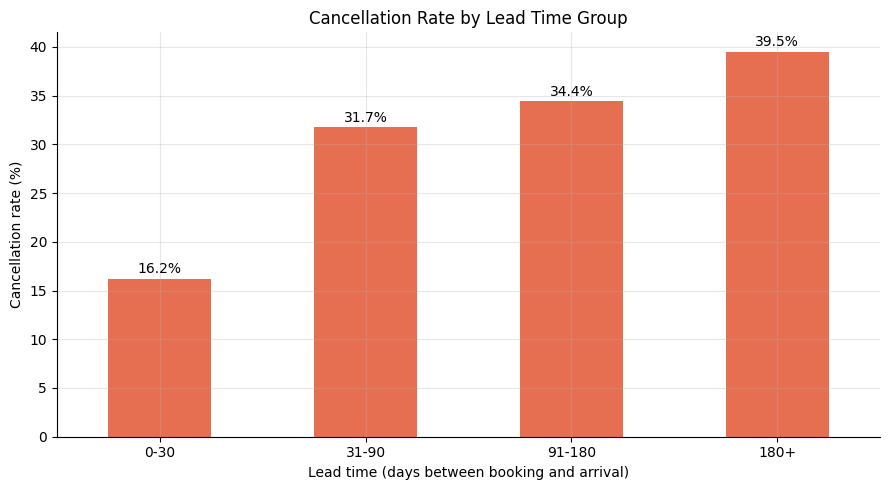

Takeaway: The longer the lead time, the higher the cancellation rate (16.2% for 0-30 days vs 39.5% for 180+ days).


In [ ]:
bins = [-1, 30, 90, 180, df["lead_time"].max()]
labels = ["0-30", "31-90", "91-180", "180+"]
df["lead_time_group"] = pd.cut(df["lead_time"], bins=bins, labels=labels)

c4 = df.groupby("lead_time_group", observed=True)["is_canceled"].mean() * 100

ax = c4.plot(kind="bar", color="#e76f51", rot=0)
ax.set_title("Cancellation Rate by Lead Time Group")
ax.set_xlabel("Lead time (days between booking and arrival)")
ax.set_ylabel("Cancellation rate (%)")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2)
save_chart("04_cancellation_by_lead_time")

print(f"Takeaway: The longer the lead time, the higher the cancellation rate ({c4.iloc[0]:.1f}% for 0-30 days vs {c4.iloc[-1]:.1f}% for 180+ days).")

### Chart 5 – Cancellation rate by market segment

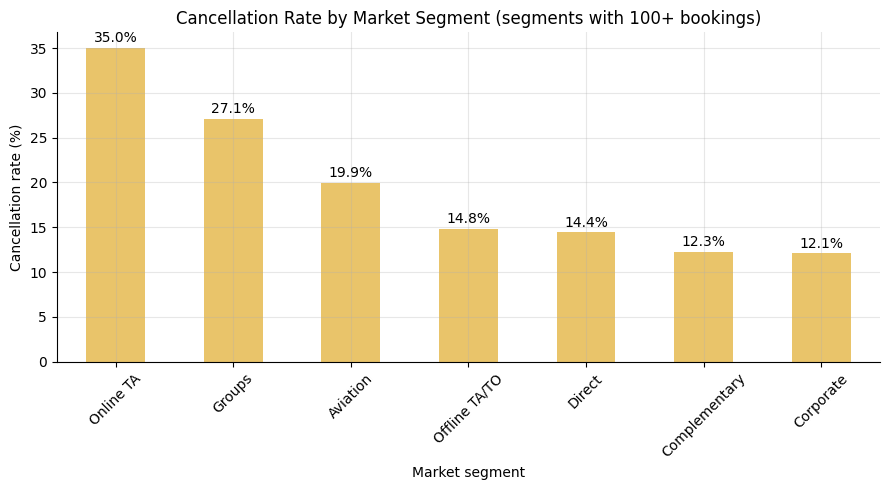

Takeaway: 'Online TA' bookings cancel most (35.0%), while 'Corporate' cancel least (12.1%).


In [ ]:
seg = df.groupby("market_segment")["is_canceled"].agg(["mean", "size"])
seg = seg[seg["size"] >= 100]          # ignore tiny segments (e.g. 'Undefined') that give misleading rates
c5 = (seg["mean"] * 100).sort_values(ascending=False)

ax = c5.plot(kind="bar", color="#e9c46a", rot=45)
ax.set_title("Cancellation Rate by Market Segment (segments with 100+ bookings)")
ax.set_xlabel("Market segment")
ax.set_ylabel("Cancellation rate (%)")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2)
save_chart("05_cancellation_by_market_segment")

print(f"Takeaway: '{c5.index[0]}' bookings cancel most ({c5.iloc[0]:.1f}%), while '{c5.index[-1]}' cancel least ({c5.iloc[-1]:.1f}%).")

### Chart 6 – Top 10 guest countries by number of bookings

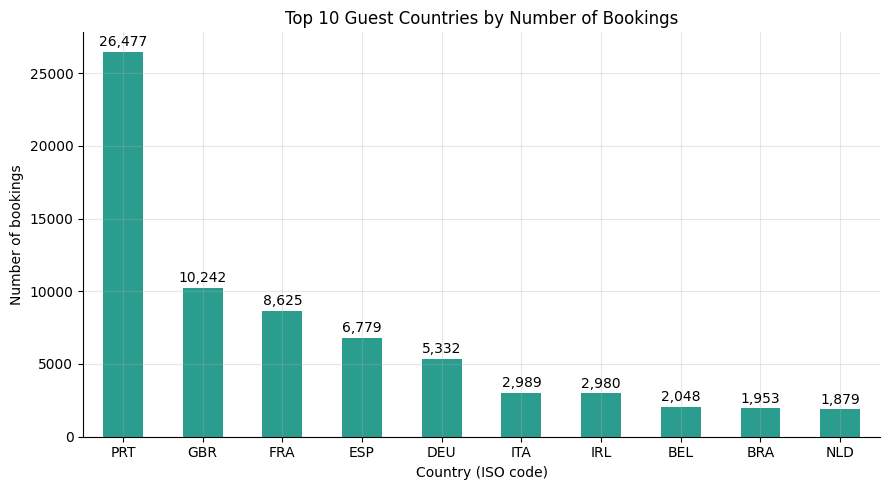

Takeaway: Most guests come from PRT (Portugal) - 31.3% of all bookings - followed by GBR and FRA.


In [ ]:
c6 = df["country"].astype(str).value_counts().head(10)

ax = c6.plot(kind="bar", color="#2a9d8f", rot=0)
ax.set_title("Top 10 Guest Countries by Number of Bookings")
ax.set_xlabel("Country (ISO code)")
ax.set_ylabel("Number of bookings")
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=2)
save_chart("06_top10_countries")

print(f"Takeaway: Most guests come from {c6.index[0]} (Portugal) - {c6.iloc[0] / len(df):.1%} of all bookings - followed by {c6.index[1]} and {c6.index[2]}.")

### Chart 7 – Cancellation rate by customer type

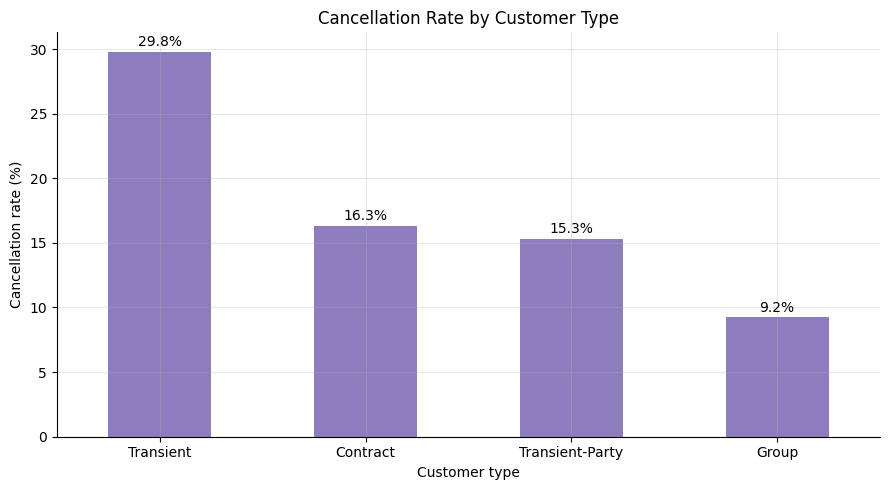

Takeaway: 'Transient' customers cancel most (29.8%); 'Group' customers cancel least (9.2%).


In [ ]:
c7 = (df.groupby("customer_type")["is_canceled"].mean() * 100).sort_values(ascending=False)

ax = c7.plot(kind="bar", color="#8e7dbe", rot=0)
ax.set_title("Cancellation Rate by Customer Type")
ax.set_xlabel("Customer type")
ax.set_ylabel("Cancellation rate (%)")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2)
save_chart("07_cancellation_by_customer_type")

print(f"Takeaway: '{c7.index[0]}' customers cancel most ({c7.iloc[0]:.1f}%); '{c7.index[-1]}' customers cancel least ({c7.iloc[-1]:.1f}%).")

## 4. Short Insights Report
The numbers below are generated directly from the cleaned data, so they always match the charts.

In [ ]:
from IPython.display import Markdown, display

overall = df["is_canceled"].mean() * 100
report = f'''
### 1) Data quality
- Raw data: **{rows_before:,} rows x {cols_before} columns**; cleaned data: **{rows_after:,} rows x {df.shape[1]} columns**.
- Fixed: missing `agent`/`children` filled with 0, missing `country` set to "Unknown", `company` dropped (mostly empty).
- Removed **{dups:,} duplicate rows**, **{zero_guest:,} zero-guest bookings** and **{adr_bad:,} rows with negative/extreme ADR** (IQR rule).
- Dates converted to datetime; `agent` and `country` converted to categories.

### 2) Key findings
1. **Overall cancellation rate is {overall:.1f}%**; City Hotel cancels more than Resort Hotel (Chart 1).
2. **Bookings are seasonal**: busiest in {by_month.idxmax()}, quietest in {by_month.idxmin()} (Chart 2).
3. **ADR (price) follows the seasons**: Resort Hotel peaks in {adr_m['Resort Hotel'].idxmax()}, City Hotel in {adr_m['City Hotel'].idxmax()} (Chart 3).
4. **Longer lead time = more cancellations**: {c4.iloc[0]:.1f}% (0-30 days) vs {c4.iloc[-1]:.1f}% (180+ days) (Chart 4).
5. **Segment and customer type matter**: '{c5.index[0]}' ({c5.iloc[0]:.1f}%) and '{c7.index[0]}' ({c7.iloc[0]:.1f}%) cancel most (Charts 5 and 7). Portugal is the top source country (Chart 6).

### 3) Recommendations
- **Ask for deposits** (or offer non-refundable rates) on bookings with a long lead time.
- **Run summer price campaigns** and raise rates in peak months; use discounts to fill low-demand winter months.
- **Focus marketing on segments** and customer types with fewer cancellations, and apply stricter policies to high-cancellation ones.
- Target the top guest countries with tailored offers.

### 4) Limitations
- The data covers only **two hotels in Portugal over about two years (2015-2017)**, so results may not apply elsewhere.
- The analysis **describes patterns but does not prove causes**.
'''
display(Markdown(report))


### 1) Data quality
- Raw data: **119,390 rows x 32 columns**; cleaned data: **84,714 rows x 34 columns**.
- Fixed: missing `agent`/`children` filled with 0, missing `country` set to "Unknown", `company` dropped (mostly empty).
- Removed **32,001 duplicate rows**, **166 zero-guest bookings** and **2,509 rows with negative/extreme ADR** (IQR rule).
- Dates converted to datetime; `agent` and `country` converted to categories.

### 2) Key findings
1. **Overall cancellation rate is 27.2%**; City Hotel cancels more than Resort Hotel (Chart 1).
2. **Bookings are seasonal**: busiest in August, quietest in January (Chart 2).
3. **ADR (price) follows the seasons**: Resort Hotel peaks in August, City Hotel in May (Chart 3).
4. **Longer lead time = more cancellations**: 16.2% (0-30 days) vs 39.5% (180+ days) (Chart 4).
5. **Segment and customer type matter**: 'Online TA' (35.0%) and 'Transient' (29.8%) cancel most (Charts 5 and 7). Portugal is the top source country (Chart 6).

### 3) Recommendations
- **Ask for deposits** (or offer non-refundable rates) on bookings with a long lead time.
- **Run summer price campaigns** and raise rates in peak months; use discounts to fill low-demand winter months.
- **Focus marketing on segments** and customer types with fewer cancellations, and apply stricter policies to high-cancellation ones.
- Target the top guest countries with tailored offers.

### 4) Limitations
- The data covers only **two hotels in Portugal over about two years (2015-2017)**, so results may not apply elsewhere.
- The analysis **describes patterns but does not prove causes**.


## 5. Export Cleaned Data & Charts

In [ ]:
df.to_csv("data/hotel_bookings_cleaned.csv", index=False)
print("Saved: data/hotel_bookings_cleaned.csv")
print("Charts saved in 'charts/':", sorted(os.listdir("charts")))

Saved: data/hotel_bookings_cleaned.csv
Charts saved in 'charts/': ['01_bookings_by_hotel_cancellation.png', '02_monthly_bookings_by_hotel.png', '03_monthly_adr.png', '04_cancellation_by_lead_time.png', '05_cancellation_by_market_segment.png', '06_top10_countries.png', '07_cancellation_by_customer_type.png']


## 6. Conclusion
This notebook covered the full analysis workflow on a real hotel dataset: loading, cleaning, seven line/bar charts, and a short insights report.
The cleaned dataset and charts are exported so the project can be uploaded to GitHub: https://github.com/ayushsheladia/Hotel-Booking-Demand-Project.git

*IU2441230475 / IU2441230539 – CSE-F*